# PCA + Clustering for European Player Archetypes

In [1]:
import pandas as pd
import numpy as np

player_scores = pd.read_csv('player_model_scores.csv')
master_df = pd.read_csv('processed_master_df.csv')

df = pd.merge(player_scores, master_df, on = ['team', 'player']).drop(columns = ["total_ball_possession_events_per_match", "Unnamed: 0_x", "Unnamed: 0_y", "avg_pass_length", "defensive_effort_count"])



---

## Data Preprocessing

In [2]:
# Value Counts of Categorical Columns

for col in df.select_dtypes(include = 'object').columns:
    unique_values = df[col].nunique()
    print(f"Unique values in {col}: {unique_values}\n")
    if unique_values < 10:
        print(f"Value counts for {col}:\n{df[col].value_counts()}\n")
    print(f"Percentage of Unique Values in {col}: {unique_values/df.shape[0]*100:.2f}%\n")
    print("" + "-"*50 + "\n")

Unique values in player: 66

Percentage of Unique Values in player: 0.14%

--------------------------------------------------

Unique values in team: 5

Value counts for team:
team
Barcelona            21684
Manchester United     8149
Arsenal               7959
Liverpool             7316
Real Madrid            632
Name: count, dtype: int64

Percentage of Unique Values in team: 0.01%

--------------------------------------------------

Unique values in type: 3

Value counts for type:
type
Pass       35745
Carry       9834
Dribble      161
Name: count, dtype: int64

Percentage of Unique Values in type: 0.01%

--------------------------------------------------

Unique values in most_frequent_pass_style: 6

Value counts for most_frequent_pass_style:
most_frequent_pass_style
Right Foot    17935
Left Foot     12967
Head           1474
Other           119
No Touch         13
Right Fo          1
Name: count, dtype: int64

Percentage of Unique Values in most_frequent_pass_style: 0.01%

--------

In [3]:
# Duplicates?
print(f"The Dataset has {df.duplicated().sum()} Duplicate rows.")

The Dataset has 0 Duplicate rows.


In [4]:
# Let's Standardize all Names and Text Values

import regex as re

def name_standardizer(df):
  for col in df.select_dtypes(include = 'object').columns:
      df[col] = df[col].apply(lambda x: re.sub(' ', '_', str(x).lower()))

  display(df.sample(7))

In [5]:
name_standardizer(df)

,player,team,mean_progressive_action_score,num_events,match_id,type,standardized_timestamp,start_x,start_y,end_x,end_y,delta_x,delta_y,distance_yards,is_progressive_pass,is_progressive_carry,is_progressive_dribble,is_progressive_action,most_frequent_pass_style,league_name
1433,daley_blind,manchester_united,0.389458,2215,105501,pass,54.29,39.2,13.7,36.2,40.6,-3.0,26.9,27.07,False,False,False,False,left_foot,premier_league
26950,óscar_mingueza_garcía,barcelona,0.222271,1466,21495,pass,0.30,38.0,55.4,32.9,37.1,-5.1,-18.3,19.00,False,False,False,False,right_foot,la_liga
27894,óscar_mingueza_garcía,barcelona,0.222271,1466,67342,carry,27.64,43.6,66.0,46.9,64.2,3.3,-1.8,3.76,False,False,False,False,nan,la_liga
24870,chris_smalling,manchester_united,0.227057,1522,106250,pass,34.23,54.8,59.4,65.6,60.2,10.8,0.8,10.83,True,False,False,True,right_foot,premier_league
23583,nathaniel_edwin_clyne,liverpool,0.230211,1943,119734,pass,69.77,24.1,74.6,68.8,69.9,44.7,-4.7,44.95,False,False,False,False,right_foot,premier_league
19432,ignacio_monreal_eraso,arsenal,0.239301,2259,92902,pass,14.55,38.3,19.6,50.6,20.7,12.3,1.1,12.35,False,False,False,False,head,premier_league
22129,alberto_moreno_pérez,liverpool,0.235213,1736,119417,pass,57.53,81.6,0.1,70.9,4.2,-10.7,4.1,11.46,False,False,False,False,nan,premier_league


In [6]:
# KNNImputer for Numerical NULL Values

from sklearn.impute import KNNImputer

num_cols = df.select_dtypes(include = ['float', 'int64']).columns

knn_imputer = KNNImputer(n_neighbors = 5)
df[num_cols] = knn_imputer.fit_transform(df[num_cols])

In [7]:
# Simple Imputer for Categorical Columns

from sklearn.impute import SimpleImputer

categorical_cols = df.select_dtypes(include = ['object', 'bool']).columns

simple_imputer = SimpleImputer(strategy = "most_frequent")
df[categorical_cols] = simple_imputer.fit_transform(df[categorical_cols])

Note for this Next Step:

* In notebook `03` of this project, we had used the CLT to plot and dissect the range of values for two given Teams.
* Although there was a discernable difference and after a large number of iterations, there was no overlap and there was a decisive outperformer, the distinction was still not large.
* Thus, we can deduce that Outlier Removal should be kept manageable (5% top and 5% bottom).

In [8]:
# Outlier Removal

df['mean_progressive_action_score'] = df['mean_progressive_action_score'].clip(lower = df['mean_progressive_action_score'].quantile(0.05), upper = df['mean_progressive_action_score'].quantile(0.95))
df['distance_yards'] = df['distance_yards'].clip(lower = df['distance_yards'].quantile(0.05), upper = df['distance_yards'].quantile(0.95))

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45740 entries, 0 to 45739
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   player                         45740 non-null  object 
 1   team                           45740 non-null  object 
 2   mean_progressive_action_score  45740 non-null  float64
 3   num_events                     45740 non-null  float64
 4   match_id                       45740 non-null  float64
 5   type                           45740 non-null  object 
 6   standardized_timestamp         45740 non-null  float64
 7   start_x                        45740 non-null  float64
 8   start_y                        45740 non-null  float64
 9   end_x                          45740 non-null  float64
 10  end_y                          45740 non-null  float64
 11  delta_x                        45740 non-null  float64
 12  delta_y                        45740 non-null 



---

## Final Stage: PCA + Hierarchical Agglomerative Clustering (HCA) for Player Archetype Detection

In [10]:
# Boolean -> Integer Flags for Aggregation
for col in df.columns[df.columns.str.startswith('is_progressive_')]:
  df[col + '_num'] = df[col].astype(int)

In [11]:
# Grouping by Player, Team, and League
player_matrix = df.groupby(['player', 'team', 'league_name']).agg(
    total_events = ('num_events', 'count'),
    total_distance_yards = ('distance_yards', 'sum'),
    mean_progressive_action_score = ('mean_progressive_action_score', 'mean'),

    # Vector Progressions
    total_delta_x = ('delta_x', 'sum'),
    mean_delta_x = ('delta_x', 'mean'),
    total_delta_y = ('delta_y', 'sum'),
    mean_delta_y = ('delta_y', 'mean'),

    # Counts of progressive actions
    prog_passes = ('is_progressive_pass_num', 'sum'),
    prog_carries = ('is_progressive_carry_num', 'sum'),
    prog_dribbles = ('is_progressive_dribble_num', 'sum'),
    total_prog_actions = ('is_progressive_action_num', 'sum'),

    # Final Third Entries (start_x or end_x in attacking third >= 80)
    final_third_entries=('end_x', lambda x: (x >= 80).sum())).reset_index()

In [12]:
# Feature Engineering: Spatial Ratios & Rates
player_matrix['prog_action_ratio'] = player_matrix['total_prog_actions'] / player_matrix['total_events']
player_matrix['prog_pass_share'] = player_matrix['prog_passes'] / (player_matrix['total_prog_actions'] + 1e-5)
player_matrix['verticality_index'] = player_matrix['total_delta_x'] / (player_matrix['total_distance_yards'] + 1e-5)
player_matrix['pitch_tilt_ratio'] = player_matrix['final_third_entries'] / player_matrix['total_events']

In [13]:
# Filtering out Sample Noise (e.g., Players with fewer than 2 total recorded actions)
player_matrix_clean = player_matrix[player_matrix['total_events'] >= 2].copy()

In [14]:
print(f"Player Matrix Created! Total Unique Players: {len(player_matrix_clean)}")
display(player_matrix_clean.head(5))

Player Matrix Created! Total Unique Players: 65


,player,team,league_name,total_events,total_distance_yards,mean_progressive_action_score,total_delta_x,mean_delta_x,total_delta_y,mean_delta_y,prog_passes,prog_carries,prog_dribbles,total_prog_actions,final_third_entries,prog_action_ratio,prog_pass_share,verticality_index,pitch_tilt_ratio
0,adnan_januzaj,manchester_united,premier_league,3,46.690,0.326667,33.3,11.100000,9.3,3.100000,1,0,0,1,1,0.333333,0.999990,0.713215,0.333333
1,alberto_moreno_pérez,liverpool,premier_league,1366,27041.212,0.235213,5554.4,4.066179,14528.9,10.636091,317,0,0,317,539,0.232064,1.000000,0.205405,0.394583
2,antoine_griezmann,barcelona,la_liga,12,112.990,0.333333,-13.9,-1.158333,29.4,2.450000,2,0,0,2,6,0.166667,0.999995,-0.123020,0.500000
3,ashley_young,manchester_united,premier_league,557,10821.469,0.174839,1611.7,2.893537,-2414.7,-4.335189,99,0,0,99,241,0.177738,1.000000,0.148935,0.432675
4,bradley_shaun_smith,liverpool,premier_league,170,2946.107,0.170059,8.0,0.047059,1402.4,8.249412,29,0,0,29,58,0.170588,1.000000,0.002715,0.341176




---



In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Selecting Numeric features for the ML Pipeline
feature_cols = [
    'mean_progressive_action_score', 'total_distance_yards',
    'total_delta_x', 'mean_delta_x', 'mean_delta_y',
    'prog_passes', 'prog_carries', 'prog_dribbles',
    'prog_action_ratio', 'verticality_index', 'pitch_tilt_ratio'
]

X = player_matrix_clean[feature_cols]

# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [16]:
# Principal Component Analysis (PCA)
pca = PCA(n_components = 3)  # 3 Macro-Traits for Cleaner Visualization
X_pca = pca.fit_transform(X_scaled)

player_matrix_clean['PCA1'] = X_pca[:, 0]
player_matrix_clean['PCA2'] = X_pca[:, 1]

print(f"Explained Variance Ratio by Component: {pca.explained_variance_ratio_}")
print(f"Total Variance Retained: {sum(pca.explained_variance_ratio_)*100:.2f}%")

Explained Variance Ratio by Component: [0.41961181 0.2576664  0.09998905]
Total Variance Retained: 77.73%


In [17]:
# Silhoette Score to Calculate Optimal Cluster (Archetype) Count
from sklearn.metrics import silhouette_score

# Quick 80/20 evaluation loop for optimal clusters
for k in range(3, 10):
    hac_test = AgglomerativeClustering(n_clusters = k, linkage='ward')
    labels = hac_test.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"Clusters (k = {k}): Silhouette Score = {score:.4f}") # Highest Silhouette Score = Optimal = 3

Clusters (k = 3): Silhouette Score = 0.1908
Clusters (k = 4): Silhouette Score = 0.2134
Clusters (k = 5): Silhouette Score = 0.2138
Clusters (k = 6): Silhouette Score = 0.2129
Clusters (k = 7): Silhouette Score = 0.2226
Clusters (k = 8): Silhouette Score = 0.2277
Clusters (k = 9): Silhouette Score = 0.2463


In [18]:
# Hierarchical Agglomerative Clustering (HAC)
hac = AgglomerativeClustering(n_clusters = 3, linkage = 'ward') # no. of Clusters = no. of Archetypes
player_matrix_clean['cluster'] = hac.fit_predict(X_scaled) + 1

# Interpreting PCA Loadings (What do PCA1 and PCA2 actually represent?)
loadings = pd.DataFrame(
    pca.components_.T,
    columns = ['PCA1_Loading', 'PCA2_Loading', 'PCA3_Loading'],
    index = feature_cols)

print("\n--- Feature Loadings for PCA Axes ---")
display(loadings.sort_values(by = 'PCA1_Loading', ascending = False))


--- Feature Loadings for PCA Axes ---


,PCA1_Loading,PCA2_Loading,PCA3_Loading
total_delta_x,0.395425,0.300481,-0.010987
mean_delta_x,0.390240,-0.293700,-0.076395
verticality_index,0.368942,-0.271131,-0.110763
mean_progressive_action_score,0.367469,-0.271872,0.086741
prog_passes,0.362312,0.384980,-0.057576
prog_action_ratio,0.361503,-0.300334,-0.138324
total_distance_yards,0.310406,0.457861,-0.107454
mean_delta_y,0.090614,0.123870,0.887854
prog_carries,0.075963,0.449352,-0.152681
prog_dribbles,-0.000000,0.000000,0.000000


### 🧠 Tactical Interpretation Guide for the Results

When analyzing  Clusters, we will use these baseline Tactical Mappings based on Feature Averages:

Cluster Profile Signatures | Tactical Archetype Label | Benchmark Exemplars

High pitch_tilt_ratio & High prog_dribbles | Vertical Winger / Final-Third Penetrator | Vinícius Jr., Ousmane Dembélé

High total_delta_x & High prog_passes | Deep-Lying Playmaker / Volume Progressor | Toni Kroos, Luka Modrić

High verticality_index & Medium prog_carries | Direct Transition Carrier | Federico Valverde, Marcos Llorente

Low pitch_tilt_ratio & High mean_delta_y | Tempo-Setting Recycler / Holding Mid | Sergio Busquets, Rodri

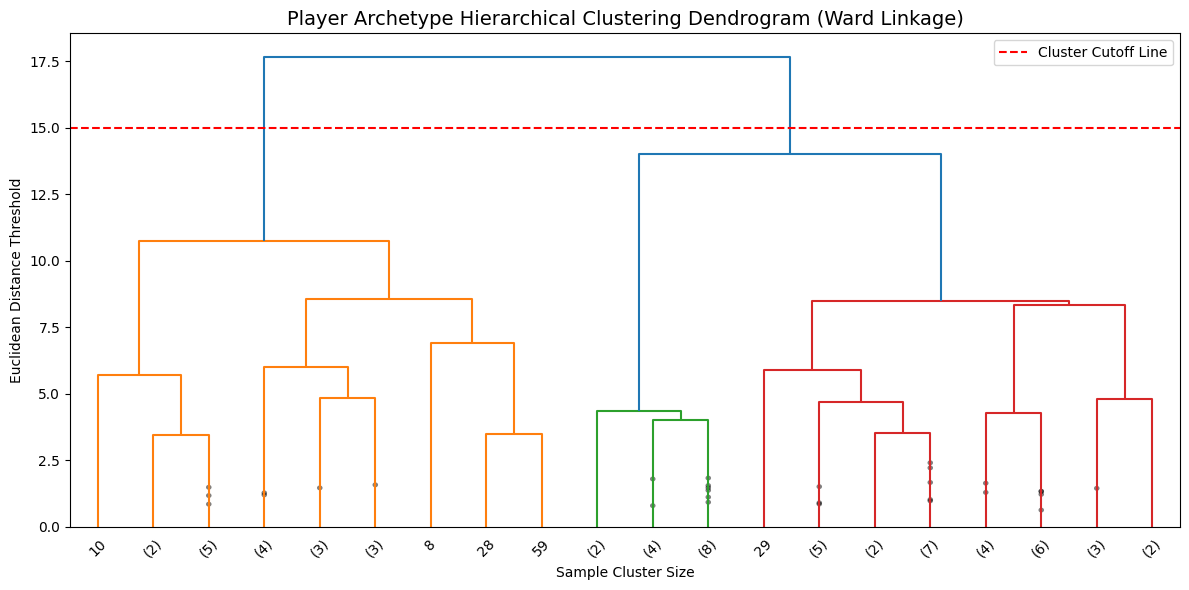

In [19]:
plt.figure(figsize = (12, 6))
plt.title("Player Archetype Hierarchical Clustering Dendrogram (Ward Linkage)", fontsize = 14)
linked = linkage(X_scaled, method = 'ward')
dendrogram(linked, truncate_mode = 'lastp', p = 20, leaf_rotation = 45, leaf_font_size = 10, show_contracted = True)
plt.xlabel("Sample Cluster Size")
plt.ylabel("Euclidean Distance Threshold")
plt.axhline(y = 15, color = 'r', linestyle = '--', label = 'Cluster Cutoff Line')
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 2. Assign 3D coordinates to DataFrame
player_matrix_clean['PCA1'] = X_pca[:, 0]
player_matrix_clean['PCA2'] = X_pca[:, 1]
player_matrix_clean['PCA3'] = X_pca[:, 2]

# 3. List of Benchmark Elite Players to Highlight
benchmarks = ['Lionel Andrés Messi Cuccittini', 'Luka Modrić', 'Pedri', 'Karim Benzema']

# Flag benchmarks in DataFrame for distinct visual markers
player_matrix_clean['is_benchmark'] = player_matrix_clean['player'].apply(
    lambda name: any(b.lower() in str(name).lower() for b in benchmarks)
)

# 4. Create Interactive 3D Scatter Plot
fig = px.scatter_3d(
    player_matrix_clean,
    x = 'PCA1',
    y = 'PCA2',
    z = 'PCA3',
    color = 'cluster',
    symbol = 'is_benchmark',
    symbol_sequence = ['circle', 'diamond-open'],
    hover_name = 'player',
    hover_data = ['team', 'league_name', 'total_prog_actions', 'verticality_index'],
    title = f"<b>European Player Archetype Matrix (3D PCA + HAC)</b><br>"
          f"<sup>Explained Variance: PCA1 ({pca.explained_variance_ratio_[0]*100:.1f}%) | "
          f"PCA2 ({pca.explained_variance_ratio_[1]*100:.1f}%) | "
          f"PCA3 ({pca.explained_variance_ratio_[2]*100:.1f}%)</sup>",
    labels = {
        'PCA1': f'PCA 1: Progression ({pca.explained_variance_ratio_[0]*100:.1f}%)',
        'PCA2': f'PCA 2: Verticality ({pca.explained_variance_ratio_[1]*100:.1f}%)',
        'PCA3': f'PCA 3: Pitch Tilt ({pca.explained_variance_ratio_[2]*100:.1f}%)',
        'cluster': 'Archetype Cluster'
    },
    template = 'plotly_dark',
    color_continuous_scale = px.colors.sequential.Reds,
    opacity = 0.85
)

# 5. Add Text Annotations for Elite Benchmarks directly in 3D Space
benchmark_df = player_matrix_clean[player_matrix_clean['is_benchmark']]

for _, row in benchmark_df.iterrows():
    fig.add_trace(
        go.Scatter3d(
            x = [row['PCA1']],
            y = [row['PCA2']],
            z = [row['PCA3']],
            mode = 'text+markers',
            text = [f"<b>{row['player'].split()[-1]}</b>"],
            textposition = "top center",
            marker = dict(size = 8, color = 'yellow', symbol = 'diamond'),
            name = row['player'],
            showlegend = False
        )
    )

# 6. Formatting Layout
fig.update_traces(marker = dict(size = 5))
fig.update_layout(
    width = 1000,
    height = 750,
    scene = dict(
        xaxis = dict(backgroundcolor = "rgb(20, 20, 20)", gridcolor = "gray"),
        yaxis = dict(backgroundcolor = "rgb(20, 20, 20)", gridcolor = "gray"),
        zaxis = dict(backgroundcolor = "rgb(20, 20, 20)", gridcolor = "gray"),
    ),
    legend = dict(x = 0.02, y = 0.98)
)

fig.show()

In [21]:
# Define core metric names for radar & violin comparisons
radar_features = [
    'mean_progressive_action_score',
    'total_delta_x',
    'mean_delta_x',
    'prog_action_ratio',
    'verticality_index',
    'pitch_tilt_ratio'
]

# Calculate cluster mean readings (Normalized to 0-100 Percentiles for clean Radar viewing)
cluster_means = player_matrix_clean.groupby('cluster')[radar_features].mean()
cluster_percentiles = cluster_means.rank(pct = True) * 100

# ------------------------------------------------------------------
# INTERACTIVE RADAR CHART WITH DROPDOWN MENU
# ------------------------------------------------------------------
fig_radar = go.Figure()

# Add a radar trace for each cluster (Archetype)
for cluster_id in sorted(player_matrix_clean['cluster'].unique()):
    values = cluster_percentiles.loc[cluster_id].values.tolist()
    # Close the radar loop by repeating the first value
    values += values[:1]
    categories = radar_features + [radar_features[0]]

    fig_radar.add_trace(go.Scatterpolar(
        r=values,
        theta=categories,
        fill='toself',
        name=f'Archetype Cluster {cluster_id}',
        visible=(cluster_id == 0) # Only first cluster visible initially
    ))

# Build Dropdown Menu Buttons
dropdown_buttons = []
for i, cluster_id in enumerate(sorted(player_matrix_clean['cluster'].unique())):
    # Visibility array: True for target cluster, False for others
    visible_mask = [False] * len(player_matrix_clean['cluster'].unique())
    visible_mask[i] = True

    dropdown_buttons.append(dict(
        label=f"Archetype Cluster {cluster_id}",
        method="update",
        args=[{"visible": visible_mask},
              {"title": f"<b>Tactical Profile: Archetype Cluster {cluster_id}</b>"}]
    ))

# Add 'Show All Clusters' Option
visible_all = [True] * len(player_matrix_clean['cluster'].unique())
dropdown_buttons.append(dict(
    label="Compare All Clusters",
    method="update",
    args=[{"visible": visible_all},
          {"title": "<b>Tactical Profile: Archetype Overlay Comparison</b>"}]
))

fig_radar.update_layout(
    updatemenus=[dict(
        active=0,
        buttons=dropdown_buttons,
        x=1.15,
        y=1.15,
        xanchor='right',
        yanchor='top'
    )],
    polar=dict(radialaxis=dict(visible=True, range=[0, 100])),
    title="<b>Tactical Profile: Archetype Cluster 0</b>",
    template="plotly_dark",
    width=800,
    height=600
)

fig_radar.show()

In [22]:
# 1. Defining the features/PCs you want available in the dropdown
dropdown_targets = ['PCA1', 'PCA2', 'PCA3', 'verticality_index', 'prog_action_ratio', 'pitch_tilt_ratio']

# Mapping technical column names to polished visual titles
title_mapping = {
    'PCA1': 'PCA Axis 1: Progressive Output & Pitch Tilt',
    'PCA2': 'PCA Axis 2: Vertical Carrying vs. Lateral Recycling',
    'PCA3': 'PCA Axis 3: Final Third Dominance',
    'verticality_index': 'Verticality Index (Forward / Total Distance)',
    'prog_action_ratio': 'Progressive Action Ratio',
    'pitch_tilt_ratio': 'Pitch Tilt Ratio (Final Third Share)'
}

# 2. Building base figure with the initial trace (PCA1)
fig_violin = go.Figure()

# Colors matching our cluster palette
unique_clusters = sorted(player_matrix_clean['cluster'].unique())

for cluster_id in unique_clusters:
    cluster_data = player_matrix_clean[player_matrix_clean['cluster'] == cluster_id]

    fig_violin.add_trace(go.Violin(
        x=cluster_data['cluster'],
        y=cluster_data['PCA1'],  # Default y-axis
        name=f"Cluster {cluster_id}",
        box_visible=True,
        meanline_visible=True,
        points='all',  # Shows individual player dots
        jitter=0.25,
        hovertext=cluster_data['player'] + " (" + cluster_data['team'] + ")",
        hoverinfo='text+y'
    ))

# Construct Dropdown Buttons to update y-data across all cluster traces
dropdown_buttons = []

for target_col in dropdown_targets:
    # Update y-values for each cluster trace dynamically
    y_updates = [
        player_matrix_clean[player_matrix_clean['cluster'] == c][target_col]
        for c in unique_clusters
    ]

    dropdown_buttons.append(dict(
        label=target_col,
        method="update",
        args=[
            {"y": y_updates},  # Update y-data array for each trace
            {
                "title": f"<b>{title_mapping.get(target_col, target_col)} Across Archetypes</b>",
                "yaxis": {"title": title_mapping.get(target_col, target_col)}
            }
        ]
    ))

# Applying layout configuration & adding dropdown selector
fig_violin.update_layout(
    title = f"<b>{title_mapping['PCA1']} Across Archetypes</b>",
    xaxis = dict(title = "Archetype Cluster", tickmode = 'array', tickvals = unique_clusters),
    yaxis = dict(title = title_mapping['PCA1']),
    template = "plotly_dark",
    violingap = 0.3,
    violingroupgap = 0.1,
    updatemenus = [dict(
        active = 0,
        buttons = dropdown_buttons,
        x = 1.15,
        y = 1.15,
        xanchor = 'right',
        yanchor = 'top'
    )],
    width = 950,
    height = 550,
    showlegend = True
)

fig_violin.show()



---

# AI Engineering - Final Phase of the Project: Data Export for Subsquent LLM Copilot

In [27]:
import json

# Core Export Features
export_cols = [
    'player',
    'team',
    'league_name',
    'cluster',
    'PCA1',
    'PCA2',
    'PCA3',
    'verticality_index',
    'prog_action_ratio',
    'pitch_tilt_ratio',
    'total_prog_actions',
    'total_events',
    'final_third_entries'
]

# Saving the Export Features as a Parquet Matrix
player_matrix_clean[export_cols].to_parquet(
    'player_matrix_clean.parquet',
    index = False
)

# Extracting Cluster Mean Profiles and Calculating Percentile Ranks
radar_features = [
    'mean_progressive_action_score',
    'total_delta_x',
    'mean_delta_x',
    'prog_action_ratio',
    'verticality_index',
    'pitch_tilt_ratio'
]

cluster_summary = player_matrix_clean.groupby('cluster')[radar_features].mean()
cluster_percentiles = cluster_summary.rank(pct = True) * 100

# Structuring Cluster Profiles' Dictionary for JSON Export
cluster_dict = {}

for cluster_id in sorted(player_matrix_clean['cluster'].unique()):
  cluster_dict[int(cluster_id)] = {
      'means': cluster_summary.loc[cluster_id].to_dict(),
      'percentiles': cluster_percentiles.loc[cluster_id].to_dict(),
      'player_count': int(
          (player_matrix_clean['cluster'] == cluster_id).sum()
      ),
  }

with open('archetype_profiles.json', 'w') as f:
  json.dump(cluster_dict, f, indent = 4)

print("✅ Export Complete: player_matrix_clean.parquet & archetype_profiles.json!")

✅ Export Complete: player_matrix_clean.parquet & archetype_profiles.json!


In [38]:
# Tool 1: Vector Similarity Tool Function
# Calculates Euclidean distance in 3D PCA space to find Player clones

def find_similar_clones(player_name: str, top_n: int = 5) -> pd.DataFrame:
  """Calculates 3D Euclidean distance across PCA coordinates (PCA1, PCA2, PCA3)

  to identify the top N nearest tactical clones for a given player.
  """

  df = pd.read_parquet('player_matrix_clean.parquet')

  # Case-insensitive lookup
  target_matches = df[
      df['player'].str.lower().str.contains(player_name.lower())
  ]
  if target_matches.empty:
    raise ValueError(
        f"Player '{player_name}' was not found in the dataset matrix."
    )

  target = target_matches.iloc[0]
  target_vec = np.array([target['PCA1'], target['PCA2'], target['PCA3']])

  # Vectorized 3D Euclidean distance calculation
  all_vecs = df[['PCA1', 'PCA2', 'PCA3']].values
  df['euclidean_distance'] = np.linalg.norm(all_vecs - target_vec, axis=1)

  # Sort by closest distance and exclude the Queried player
  clones = (
      df[df['player'] != target['player']]
      .sort_values('euclidean_distance')
      .head(top_n)
  )

  return clones[[
      'player',
      'team',
      'league_name',
      'cluster',
      'euclidean_distance',
      'verticality_index',
      'pitch_tilt_ratio',
  ]]


# Verification Test
display(find_similar_clones("antoine_griezmann", top_n = 5))

,player,team,league_name,cluster,euclidean_distance,verticality_index,pitch_tilt_ratio
22,héctor_junior_firpo_adames,barcelona,la_liga,2,0.448191,0.027159,0.330317
4,bradley_shaun_smith,liverpool,premier_league,2,1.045616,0.002715,0.341176
16,francisco_antónio_machado_mota_de_castro_trincão,barcelona,la_liga,2,1.046860,0.033437,0.368000
15,ferland_mendy,real_madrid,la_liga,2,1.141978,0.270340,0.226027
30,josé_ignacio_fernández_iglesias,real_madrid,la_liga,2,1.375839,0.223850,0.186275


In [ ]:
# Tool 2: Squad Composition Analysis

def analyze_squad_balance(player_list: list) -> dict:
    """
    Evaluates a starting XI or squad list against the archetype cluster distributions.
    Identifies cluster over-concentrations and flags missing tactical profiles.
    """
    df = pd.read_parquet("player_matrix_clean.parquet")

    # Load cluster archetype taxonomy mapping
    cluster_taxonomy = {
        0: "Tempo-Setting Recyclers (High Volume / Lateral Passers)",
        1: "Vertical Ball-Carriers / Transition Engines (High Carries / High Delta X)",
        2: "Final-Third Penetrators / Primary Creators (High Pitch Tilt / Box Entries)",
        3: "Direct Wingers / 1v1 Take-On Specialists (High Dribbles / Wide Y Displacement)",
        4: "Defensive Anchor / Ball Recovery Specialists"
    }

    # Filter squad players from matrix
    squad_df = df[df['player'].str.lower().isin([p.lower() for p in player_list])]

    missing_players = set([p.lower() for p in player_list]) - set(squad_df['player'].str.lower())

    # Calculate Cluster Distribution counts
    cluster_counts = squad_df['cluster'].value_counts().to_dict()

    # Identify present vs missing Tactical roles
    present_archetypes = {cluster_taxonomy.get(c, f"Cluster {c}"): count for c, count in cluster_counts.items()}

    all_clusters = set(range(5))
    missing_cluster_ids = all_clusters - set(cluster_counts.keys())
    missing_archetypes = [cluster_taxonomy.get(c, f"Cluster {c}") for c in missing_cluster_ids]

    # Construct Structured Output Dictionary for the LLM
    squad_report = {
        "squad_size_found": len(squad_df),
        "missing_players_not_in_database": list(missing_players),
        "archetype_distribution": present_archetypes,
        "tactical_gaps": missing_archetypes,
        "squad_averages": {
            "mean_verticality_index": float(squad_df['verticality_index'].mean()),
            "mean_pitch_tilt_ratio": float(squad_df['pitch_tilt_ratio'].mean()),
            "total_progressive_actions": float(squad_df['total_prog_actions'].sum())
        }
    }

    return squad_report

# Verification Test:
# sample_squad = ['Lionel Andrés Messi Cuccittini', 'Luka Modrić', 'Pedri', 'Karim Benzema']
# print(json.dumps(analyze_squad_balance(sample_squad), indent=2))

In [ ]:
# Tool 3: Top Players by Defined Archetype/Cluster

def get_top_archetype_players(
    cluster_id: int, top_n: int = 5, metric_sort: str = "total_prog_actions"
) -> pd.DataFrame:
  """Retrieves the top N highest-performing players within a specific tactical cluster/archetype.

  Parameters:
  - cluster_id (int): The target cluster ID (0 to 4).
  - top_n (int): Number of top players to return (default 5).
  - metric_sort (str): Metric to rank players by ('total_prog_actions',
  'verticality_index', 'pitch_tilt_ratio', 'total_events').
  """
  df = pd.read_parquet("player_matrix_clean.parquet")

  # 1. Validate cluster ID
  if cluster_id not in df["cluster"].unique():
    valid_clusters = sorted(df["cluster"].unique().tolist())
    raise ValueError(
        f"Cluster ID {cluster_id} invalid. Must be one of {valid_clusters}."
    )

  # 2. Filter by cluster
  cluster_df = df[df["cluster"] == cluster_id]

  # 3. Validate sort column
  if metric_sort not in cluster_df.columns:
    metric_sort = "total_prog_actions"

  # 4. Sort and extract top N
  top_players = cluster_df.sort_values(
      by = metric_sort, ascending = False
  ).head(top_n)

  # Map human-readable taxonomy names for context
  cluster_taxonomy = {
      0: "Tempo-Setting Recyclers",
      1: "Vertical Ball-Carriers / Transition Engines",
      2: "Final-Third Penetrators / Primary Creators",
      3: "Direct Wingers / 1v1 Take-On Specialists",
      4: "Defensive Anchor / Ball Recovery Specialists",
  }

  top_players["archetype_label"] = cluster_taxonomy.get(
      cluster_id, f"Cluster {cluster_id}"
  )

  return top_players[[
      "player",
      "team",
      "league_name",
      "archetype_label",
      "total_prog_actions",
      "verticality_index",
      "pitch_tilt_ratio",
  ]]


# Quick Verification Test:
# display(get_top_archetype_players(cluster_id=2, top_n=5, metric_sort='total_prog_actions'))